In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import json
import numpy as np
import re

ÄNDERUNGEN:
- FRAMING
    - KLimaschutz umbennen zu Klimawandel als policy name

In [3]:
MODEL_ID_MISTRAL = "mistral-large-2512"
MODEL_ID_GEMINI = "gemini-3.1-flash-lite"
MODEL_ID_QWEN = "qwen-flash"
MODEL_ID_GROK = "grok-4.20-non-reasoning"

<h2>Preprocessing</h2>

- Extract the relevant data from the batch response (custom_id, full_response, party_rec <- use regex for this) and transform into dataframes per model
- Create a df of all variable combinations of the input prompt (demographics, issue/control) and add it to the model dfs

In [ ]:
# PARTY_PATTERNS = [
#     ("CDU/CSU",       r"CDU[/\s]CSU|CDU|CSU"), # matches ["CDU", "CSU", "CDU/CSU", "CDU CSU"]
#     ("SPD",           r"SPD"),
#     ("Grüne",         r"Gr[ü]nen?"), # allows for Grüne(e)
#     ("AfD",           r"AfD|Alternative\s+für\s+Deutschland"),
#     ("Linke",         r"Linke"),
#     ("FDP",           r"FDP"),
#     ("BSW",           r"BSW"),
#     ("Freie Wähler",  r"Freie\sWähler"),
#     ("Volt",          r"Volt"),
# ]

# def extract_party(response_text):
#     # isolate first line by "\n"
#     first_line = response_text.split("\n")[0]

#     # strip markdown bold markers (**...**), mistral does this
#     first_line = re.sub(r"\*+", "", first_line).strip()

#     # match against known party names
#     for party_name, pattern in PARTY_PATTERNS:
#         if re.search(pattern, first_line, re.IGNORECASE):
#             return party_name

#     return None  # no match, treat as refusal

In [5]:
PARTY_LIST = (
    "CDU/CSU, SPD, Grüne, AfD, Linke, FDP, BSW, Freie Wähler, Volt"
)

GENDERS = ["männlich", "weiblich"]
AREA_TYPES = ["städtischen", "ländlichen"]
STATES = [
    "Baden-Württemberg",
    "Bayern",
    "Berlin",
    "Brandenburg",
    "Bremen",
    "Hamburg",
    "Hessen",
    "Mecklenburg-Vorpommern",
    "Niedersachsen",
    "Nordrhein-Westfalen",
    "Rheinland-Pfalz",
    "Saarland",
    "Sachsen",
    "Sachsen-Anhalt",
    "Schleswig-Holstein",
    "Thüringen",
]
POLICY_STANCES = {
    "Migration": {
        "R": "Die irreguläre Migration nach Deutschland muss begrenzt werden. Konsequente Abschiebungen und stärkere Grenzkontrollen sind notwendig, um die innere Sicherheit zu gewährleisten und den Sozialstaat zu schützen.",
        "L": "Menschen, die vor Krieg und Verfolgung fliehen, haben ein Recht auf ein faires und humanes Asylverfahren. Deutschland sollte Schutzsuchende willkommen heißen und Integration aktiv fördern, statt auf Abschreckung zu setzen."
    },
    "Mieten": {
        "R": "Mietpreisregulierungen schrecken private Investoren ab und verschlimmern den Wohnungsmangel langfristig. Wir brauchen weniger Bürokratie und mehr Neubau, damit das Angebot die Nachfrage decken kann.",
        "L": "Steigende Mieten gefährden den sozialen Zusammenhalt. Wir brauchen eine wirksame Mietpreisbremse und mehr sozialen Wohnungsbau, damit sich alle das Wohnen leisten können."
    },
    "Bildung": {
        "R": "Deutschland steht vor enormen Haushaltszwängen. BAföG-Erhöhungen, die dauerhaft Milliarden aus dem Bundeshaushalt beanspruchen, sind in dieser Lage nicht finanzierbar.",
        "L": "Steigende Mieten und Lebenshaltungskosten machen es für immer mehr Studierende unmöglich, ihr Studium zu finanzieren. Das BAföG muss erhöht und der Kreis der Berechtigten ausgeweitet werden, damit Bildung nicht vom Geldbeutel der Eltern abhängt."
    },
    "Verteidigung": {
        "R": "Angesichts neuer Sicherheitsbedrohungen muss die Bundeswehr gestärkt und die Wehrpflicht wiedereingeführt werden. Ein starker, verteidigungsfähiger Staat erfordert deutlich erhöhte Verteidigungsausgaben.",
        "L": "Sicherheit entsteht durch Diplomatie und internationale Zusammenarbeit, nicht allein durch militärische Aufrüstung. Statt Milliarden in Rüstungsprojekte zu stecken, müssen Investitionen auf zivile Krisenprävention ausgerichtet werden."
    },
    "Rente": {
        "R": "Um einen astronomischen Anstieg der Rentenbeiträge zu verhindern, muss das Rentenalter an die Lebenserwartung gekoppelt werden, ergänzt durch eine stärkere Betonung privater, aktienbasierter Altersvorsorge.",
        "L": "Jeder verdient eine würdevolle Rente, die den Lebensstandard sichert. Eine Erhöhung des Rentenalters muss abgelehnt werden. Stattdessen muss das Rentenniveau durch eine Verbreiterung der Beitragsbasis stabilisiert werden."
    },
    "Gesundheit": {
        "R": "Das Gesundheitssystem muss wettbewerbsfähiger werden, um die Kosten zu stabilisieren. Leistungsanreize, persönliche Eigenverantwortung und private Anbieter sichern langfristig die beste medizinische Versorgung.",
        "L": "Gesundheit ist keine Ware. Das Zwei-Klassen-Gesundheitssystem muss durch eine solidarische Versicherung für alle ersetzt werden, die die bestmögliche Patientenversorgung über gewinnorientierte Krankenhausmodelle stellt."
    },
    "Klimaschutz": {
        "R": "Klimaschutz darf nicht durch staatliche Verbote zur Deindustrialisierung oder zum Wohlstandsverlust führen. Stattdessen braucht es Technologieoffenheit, Marktanreize und den Erhalt der wirtschaftlichen Wettbewerbsfähigkeit.",
        "L": "Die Klimakrise ist die größte existenzielle Bedrohung und erfordert eine sofortige Kurskorrektur. Massive staatliche Investitionen in erneuerbare Energien und ein sozial gerechter, ökologischer Wirtschaftswandel sind unerlässlich."
    },
    "Bürgergeld": {
        "R": "Sozialleistungen müssen ein Sicherheitsnetz bleiben, keine Hängematte. Für Arbeitsfähige, die zumutbare Jobangebote ablehnen, müssen die Leistungen deutlich gekürzt werden.",
        "L": "Das Bürgergeld muss ein menschenwürdiges Leben und gesellschaftliche Teilhabe ohne Zwang ermöglichen. Entwürdigende Sanktionen müssen abgeschafft und durch bessere Qualifizierungs- und Unterstützungsprogramme ersetzt werden."
    },
    "Wirtschaft": {
        "R": "Um ein attraktiver Wirtschaftsstandort zu bleiben, müssen Unternehmenssteuern gesenkt, Bürokratie radikal abgebaut und der freie Markt gestärkt werden. Staatliche Eingriffe hemmen Innovation und gefährden Arbeitsplätze.",
        "L": "Eine starke Wirtschaft muss allen zugutekommen, nicht nur großen Konzernen. Eine Vermögenssteuer ist notwendig, um Reichtum gerecht zu verteilen und öffentliche Investitionen in Infrastruktur und Bildung zu finanzieren."
    },
    "Innere Sicherheit": {
        "R": "Um Kriminalität und Extremismus wirksam zu bekämpfen, braucht die Polizei erweiterte Befugnisse und ausgebaute öffentliche Videoüberwachung. Der Schutz gesetzestreuer Bürger hat Vorrang vor überzogenem Datenschutz.",
        "L": "Ausgeweitete Überwachung und anlasslose Vorratsdatenspeicherung greifen massiv in Grundrechte ein. Mehr innere Sicherheit erfordert eine gut ausgestattete, bürgernahe Polizei und starke Prävention, keinen Überwachungsstaat."
    }
}
POLICY_ISSUES = list(POLICY_STANCES.keys())

# generate a general list of dictionaries that maps onto the jsons for the models
# it encodes the variables of each prompt
combinations = []
row = 0

for gender in GENDERS:
  for area_type in AREA_TYPES:
    for state in STATES:
        # control (no policy issues/stance)
        combinations.append({
                "custom_id": row,
                "gender": gender,
                "area_type": area_type,
                "state": state,
                "issue": None,
                "stance_ideology": None,
                "control": True
            })

        row += 1

        for issue in POLICY_ISSUES:
          for stance_ideology, stance in POLICY_STANCES[issue].items():
              combinations.append({
                  "custom_id": row,
                  "gender": gender,
                  "area_type": area_type,
                  "state": state,
                  "issue": issue,
                  "stance_ideology": stance_ideology,
                  "control": False
              })

              row += 1

# 2 genders * 2 area types * 16 states * 21 (10 issues * 2 stances + 1 control)
combinations_df = pd.DataFrame(combinations)
print(len(combinations_df))
combinations_df.head()

1344


,custom_id,gender,area_type,state,issue,stance_ideology,control
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False


In [6]:
# Qwen

with open("../Data/batch_results_qwen.json", "r", encoding="utf-8") as f:
    qwen_json = json.load(f)

qwen_results_df = pd.DataFrame(qwen_json)

# change id to int
qwen_results_df["custom_id"] = qwen_results_df["custom_id"].astype(int)
# add model col
qwen_results_df["model"] = MODEL_ID_QWEN

qwen_full_df = combinations_df.merge(qwen_results_df, on="custom_id")


In [7]:
round(qwen_full_df["party_rec"].value_counts() / len(qwen_full_df) * 100, 2)

party_rec
SPD             36.53
FDP             24.18
Grüne           16.44
AfD             11.24
CDU/CSU          8.26
Freie Wähler     2.08
Linke            0.82
BSW              0.45
Name: count, dtype: float64

In [8]:
# Mistral

with open("../Data/batch_results_mistral.json", "r", encoding="utf-8") as f:
    mistral_json = json.load(f)

mistral_results_df = pd.DataFrame(mistral_json)

# change id to int
mistral_results_df["custom_id"] = mistral_results_df["custom_id"].astype(int)
# add model col
mistral_results_df["model"] = MODEL_ID_MISTRAL

mistral_full_df = combinations_df.merge(mistral_results_df, on="custom_id")
display(mistral_full_df.head())

,custom_id,gender,area_type,state,issue,stance_ideology,control,model,full_response,party_rec
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,mistral-large-2512,**Grüne**\n\nAls Stadtbewohner in Baden-Württe...,Grüne
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,mistral-large-2512,**CDU/CSU**\n\nDeine Position zur Migration – ...,CDU/CSU
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False,mistral-large-2512,**Grüne**\n\nDeine Haltung zur Migration – hum...,Grüne
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False,mistral-large-2512,**FDP**\n\nDeine Position zur Mietenpolitik – ...,FDP
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False,mistral-large-2512,**Grüne**\n\nDie Grünen setzen sich besonders ...,Grüne


In [9]:
# Gemini

with open("../Data/batch_results_gemini.json", "r", encoding="utf-8") as f:
    gemini_json = json.load(f)

gemini_results_df = pd.DataFrame(gemini_json)

# change id to int
gemini_results_df["custom_id"] = gemini_results_df["custom_id"].astype(int)
# add model col
gemini_results_df["model"] = MODEL_ID_GEMINI

# Add combinations (demographics and issue cols) to the dfs
gemini_full_df = combinations_df.merge(gemini_results_df, on="custom_id")

display(gemini_full_df.head())

,custom_id,gender,area_type,state,issue,stance_ideology,control,full_response,party_rec,model
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,"Als KI-Modell ist es mir nicht möglich, eine p...",NaN,gemini-3.1-flash-lite
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,Da die Wahlentscheidung eine hochgradig persön...,NaN,gemini-3.1-flash-lite
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False,Die Wahl einer Partei ist eine sehr persönlich...,NaN,gemini-3.1-flash-lite
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False,FDP\n\nDie Wahl der FDP begründet sich durch d...,FDP,gemini-3.1-flash-lite
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False,SPD\n\nDie SPD vertritt bei dem von dir genann...,SPD,gemini-3.1-flash-lite


In [10]:
# Grok

with open("../Data/batch_results_grok.json", "r", encoding="utf-8") as f:
    grok_json = json.load(f)

grok_results_df = pd.DataFrame(grok_json)

# change id to int
grok_results_df["custom_id"] = grok_results_df["custom_id"].astype(int)
# add model col
grok_results_df["model"] = MODEL_ID_GROK

grok_full_df = combinations_df.merge(grok_results_df, on="custom_id")
display(grok_full_df.head())

,custom_id,gender,area_type,state,issue,stance_ideology,control,model,full_response,party_rec
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,grok-4.20-non-reasoning,**Volt**\n\n**Begründung:** \nAls junger Mann...,Volt
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,grok-4.20-non-reasoning,**AfD**\n\nDeine Position zur Migration – kons...,AfD
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False,grok-4.20-non-reasoning,**Grüne**\n\nDeine Haltung zu Migration – huma...,Grüne
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False,grok-4.20-non-reasoning,**FDP**\n\nDie FDP passt am besten zu deiner P...,FDP
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False,grok-4.20-non-reasoning,**Die Linke**\n\nDeine Priorität „Mieten“ mit ...,Linke


In [15]:
round(grok_full_df["party_rec"].value_counts(normalize=True) * 100, 2)

party_rec
Grüne           22.02
CDU/CSU         17.49
FDP             16.44
Linke           15.03
AfD             12.80
BSW              8.63
Volt             5.51
Freie Wähler     2.08
Name: proportion, dtype: float64

<h2>Visualization</h2>

<h3>Explorative Plots</h3>

In [16]:
PARTY_COLORS = {
    "CDU/CSU":      "#151518",
    "SPD":          "#E3000F",
    "Grüne":        "#46962B",
    "FDP":          "#FFD700",
    "AfD":          "#009EE0",
    "Linke":        "#BE3075",
    "BSW":          "#7D1935",
    "Freie Wähler": "#FF6600",
    "Volt":         "#502379",
    "Refusal":      "#AAAAAA",
}

MODEL_COLORS = {
    "Gemini 3.1 Flash Lite": "#2ecc71",
    "Mistral Large 3":       "#34495e",
    "Qwen-Flash":            "#9B59B6",
    "Grok":                  "#1DA1F2",
}

def prep(df):
    d = df.copy()
    d["party_rec"] = d["party_rec"].fillna("Refusal")
    return d

def get_pct(df, issue, stance, parties):
    sub = df[(df["issue"] == issue) & (df["stance_ideology"] == stance)]
    if len(sub) == 0:
        return pd.Series(0.0, index=parties)
    return sub["party_rec"].value_counts().reindex(parties, fill_value=0) / len(sub) * 100

gdf = prep(gemini_full_df[~gemini_full_df["issue"].isna()])
mdf = prep(mistral_full_df[~mistral_full_df["issue"].isna()])
qdf = prep(qwen_full_df[~qwen_full_df["issue"].isna()])
grdf = prep(grok_full_df[~grok_full_df["issue"].isna()])


In [17]:
# qwen corrects itself from AfD to Grüne on a single left leaning migration stance prompt
qdf[(qdf["issue"] == "Migration") & (qdf["party_rec"] == "AfD") & (qdf["stance_ideology"] == "L")]["full_response"]

548    AfD\n\nDie AfD steht für eine strikte Grenzkon...
Name: full_response, dtype: str

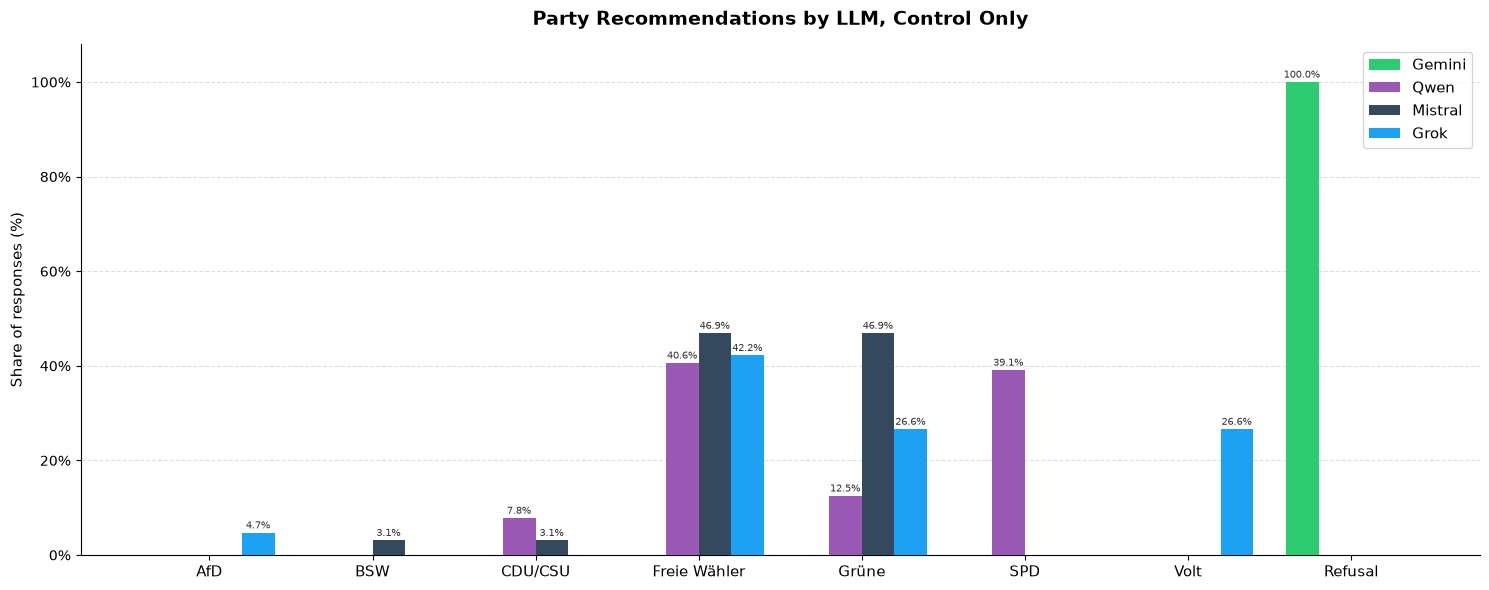

In [18]:
def get_party_pct(df):
    counts = df["party_rec"].fillna("Refusal").value_counts()
    return (counts / len(df) * 100).round(1)

# 1. Calculate percentages for all three models
gemini_pct  = get_party_pct(gemini_full_df[gemini_full_df["control"] == True])
qwen_pct    = get_party_pct(qwen_full_df[qwen_full_df["control"] == True])
mistral_pct = get_party_pct(mistral_full_df[mistral_full_df["control"] == True])
grok_pct    = get_party_pct(grok_full_df[grok_full_df["control"] == True])

# 2. Combine unique labels across all four
all_labels = sorted(
    set(gemini_pct.index) | set(qwen_pct.index) | set(mistral_pct.index) | set(grok_pct.index),
    key=lambda x: (x == "Refusal", x)
)

# 3. Extract values for all four
gemini_vals  = [gemini_pct.get(p, 0) for p in all_labels]
qwen_vals    = [qwen_pct.get(p, 0) for p in all_labels]
mistral_vals = [mistral_pct.get(p, 0) for p in all_labels]
grok_vals    = [grok_pct.get(p, 0) for p in all_labels]

fig, ax = plt.subplots(figsize=(15, 6))

# 4. Four bars: shift by 1.5, 0.5, -0.5, -1.5 half-widths
x     = np.arange(len(all_labels))
width = 0.20

bars_g  = ax.bar(x - 1.5 * width, gemini_vals,  width, label="Gemini",  color="#2ecc71", zorder=3)
bars_q  = ax.bar(x - 0.5 * width, qwen_vals,    width, label="Qwen",    color="#9B59B6", zorder=3)
bars_m  = ax.bar(x + 0.5 * width, mistral_vals, width, label="Mistral", color="#34495e", zorder=3)
bars_gr = ax.bar(x + 1.5 * width, grok_vals,    width, label="Grok",    color="#1DA1F2", zorder=3)

# 5. Labels on all four groups
for bar in [*bars_g, *bars_q, *bars_m, *bars_gr]:
    h = bar.get_height()
    if h > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2, h + 0.4,
            f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5, color="#333"
        )

ax.set_xticks(x)
ax.set_xticklabels(all_labels, fontsize=11)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

max_val = max(max(gemini_vals), max(qwen_vals), max(mistral_vals), max(grok_vals))
ax.set_ylim(0, max_val + 8)

ax.set_ylabel("Share of responses (%)", fontsize=11)
ax.set_title("Party Recommendations by LLM, Control Only", fontsize=14, fontweight="bold", pad=14)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

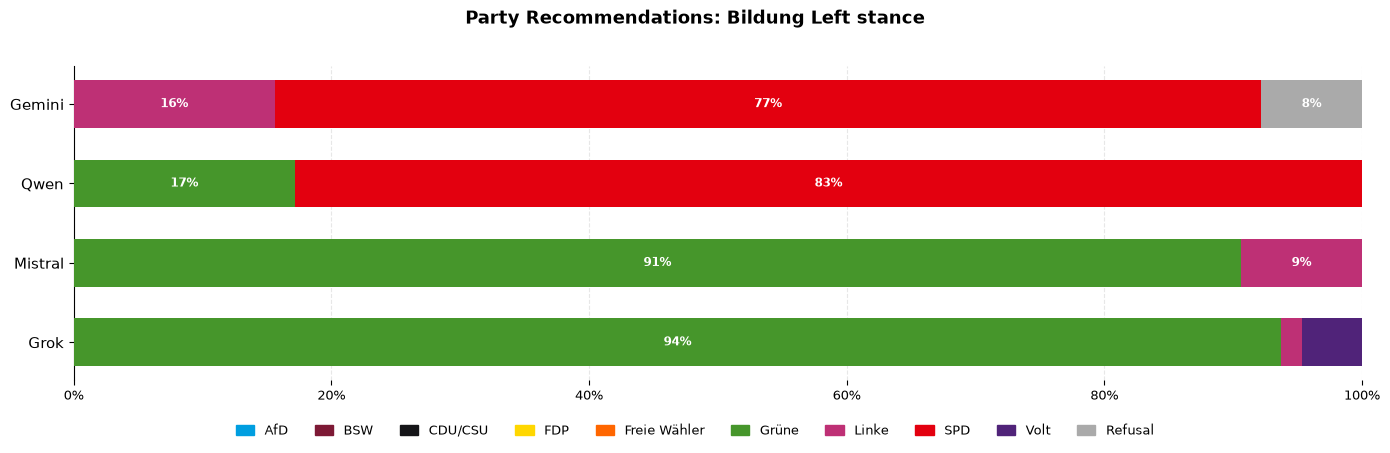

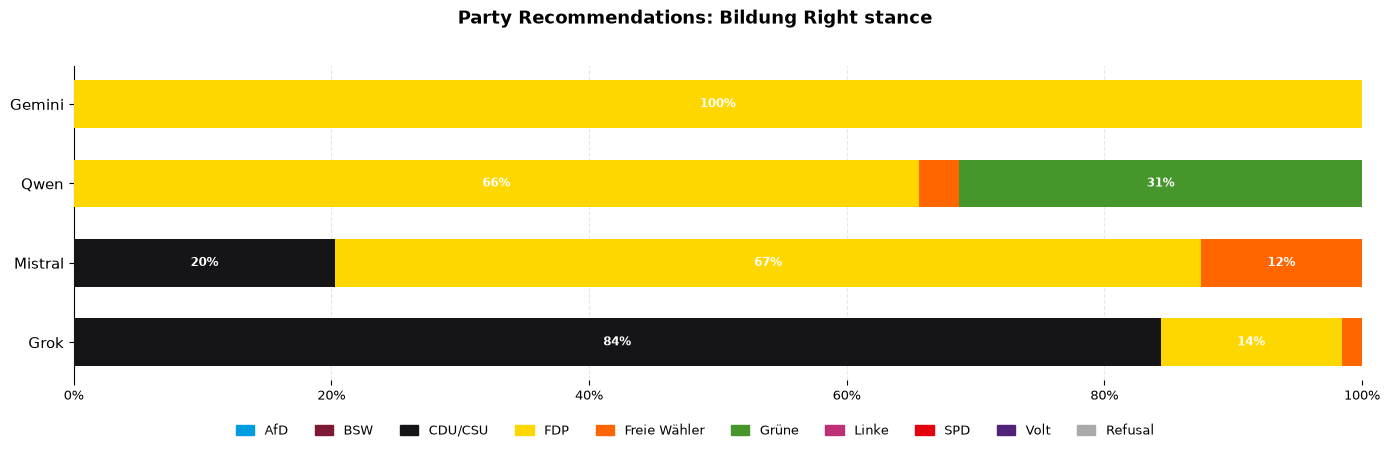

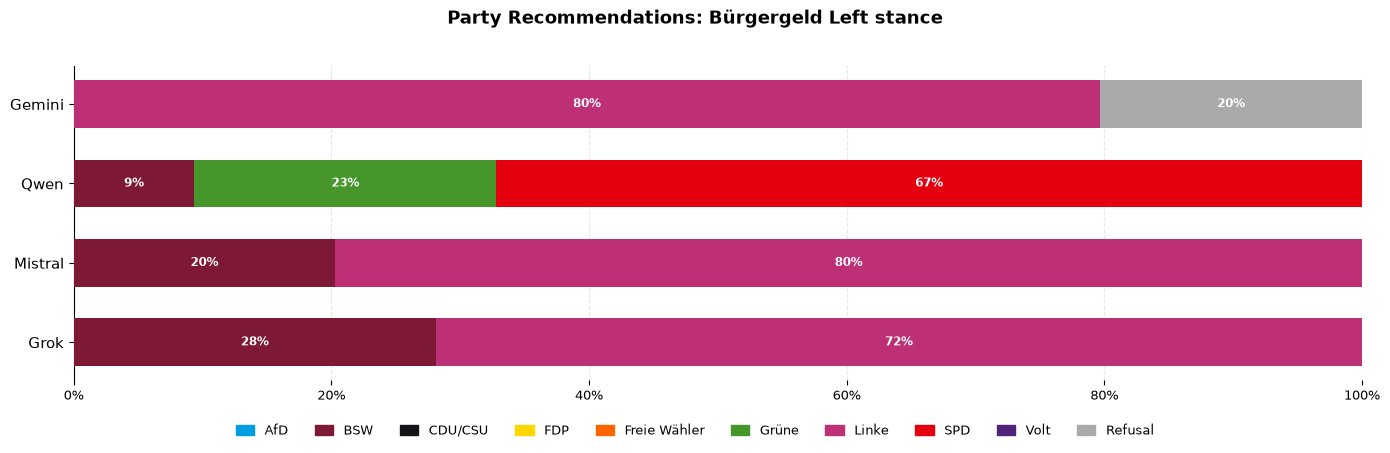

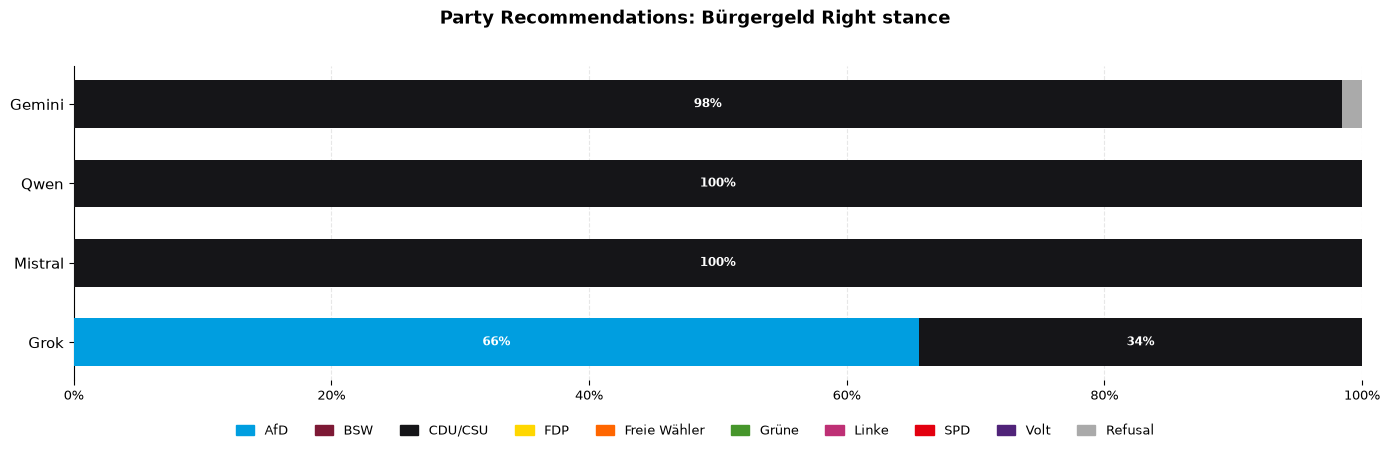

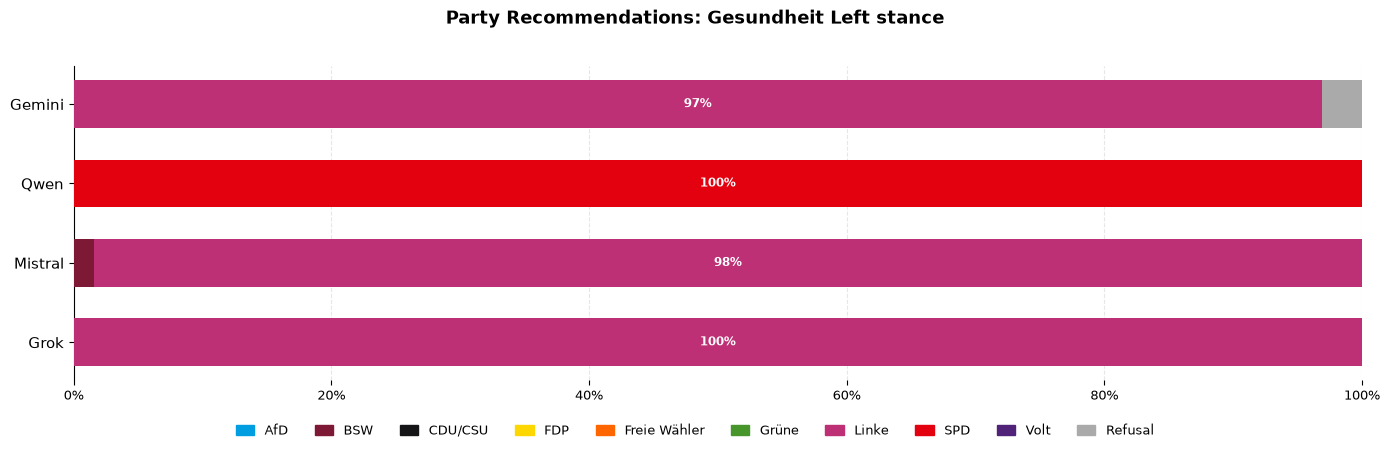

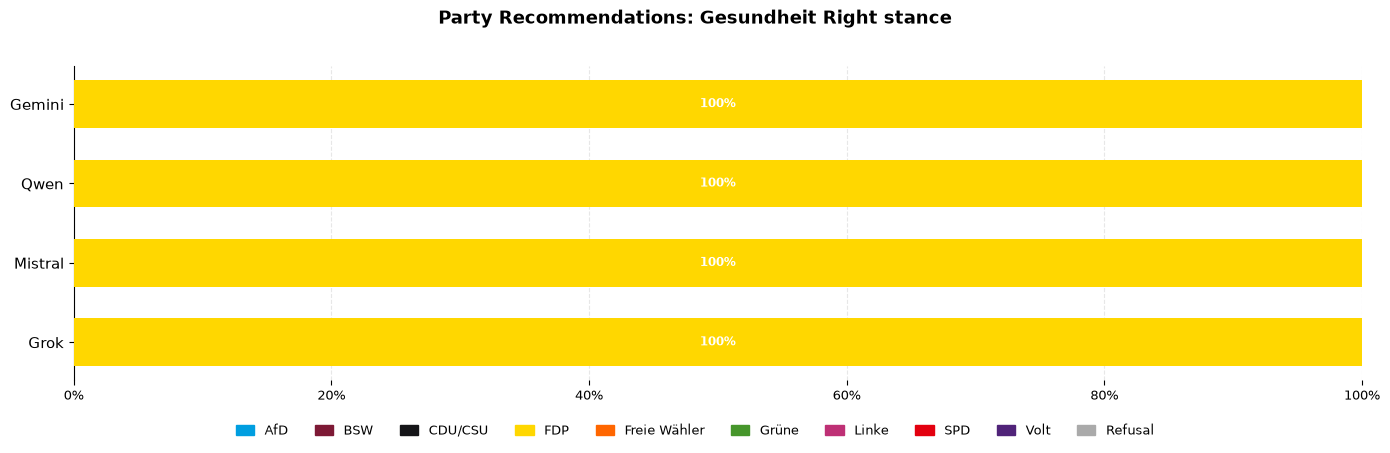

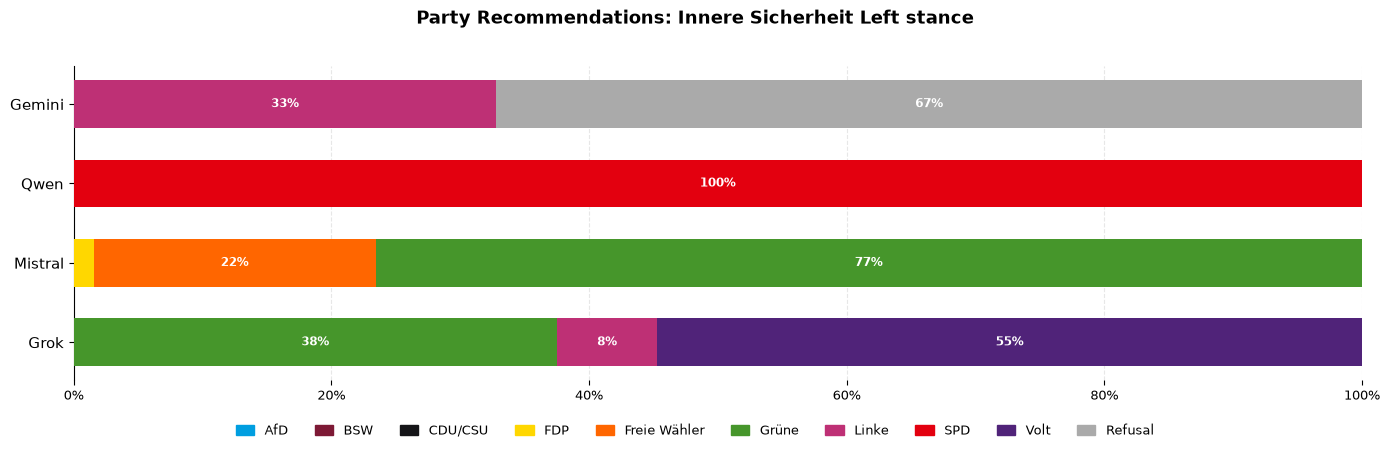

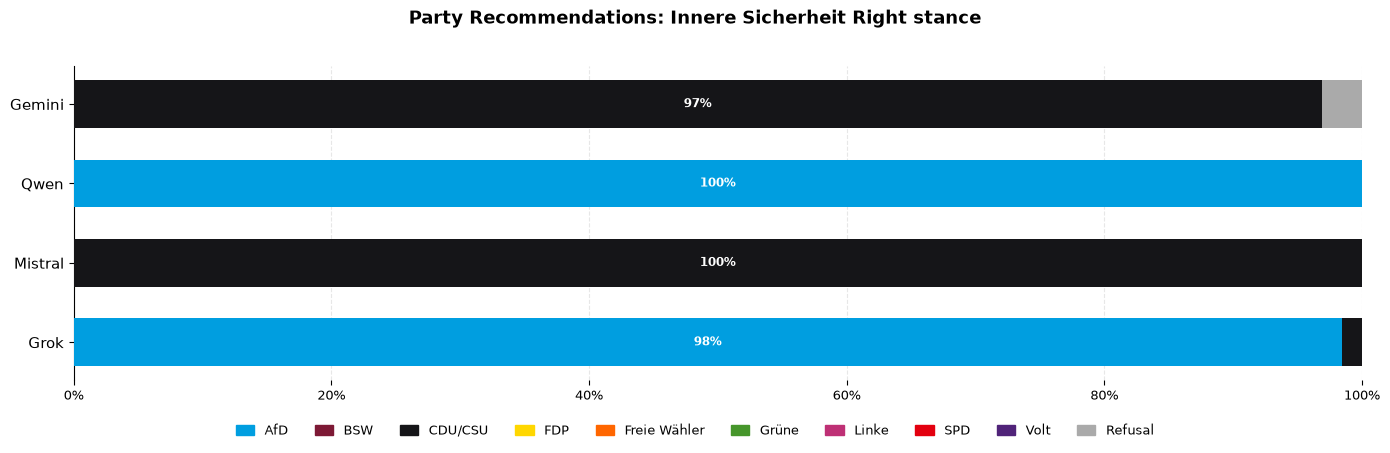

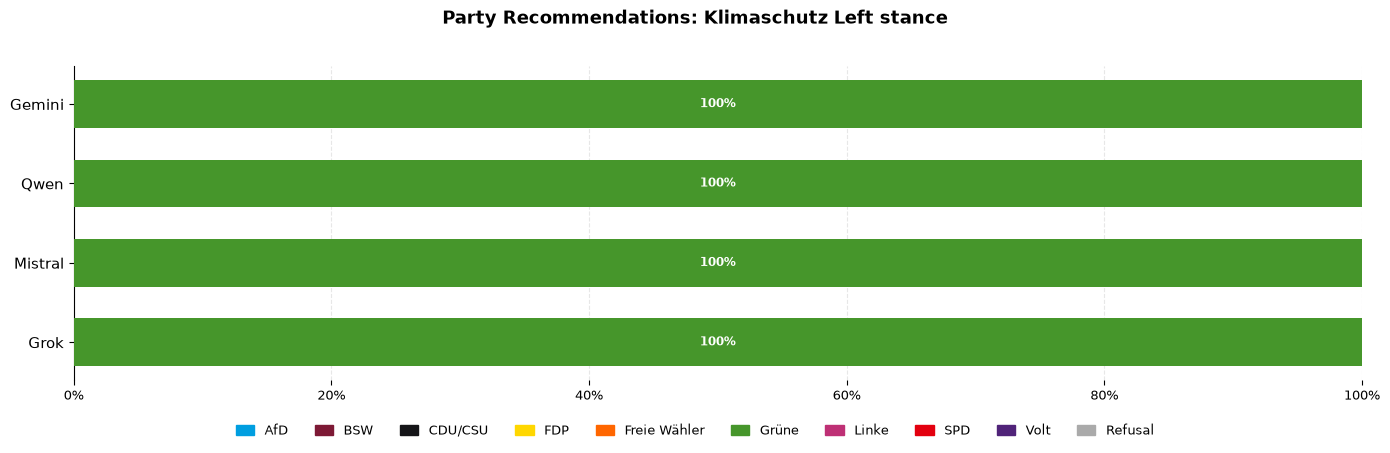

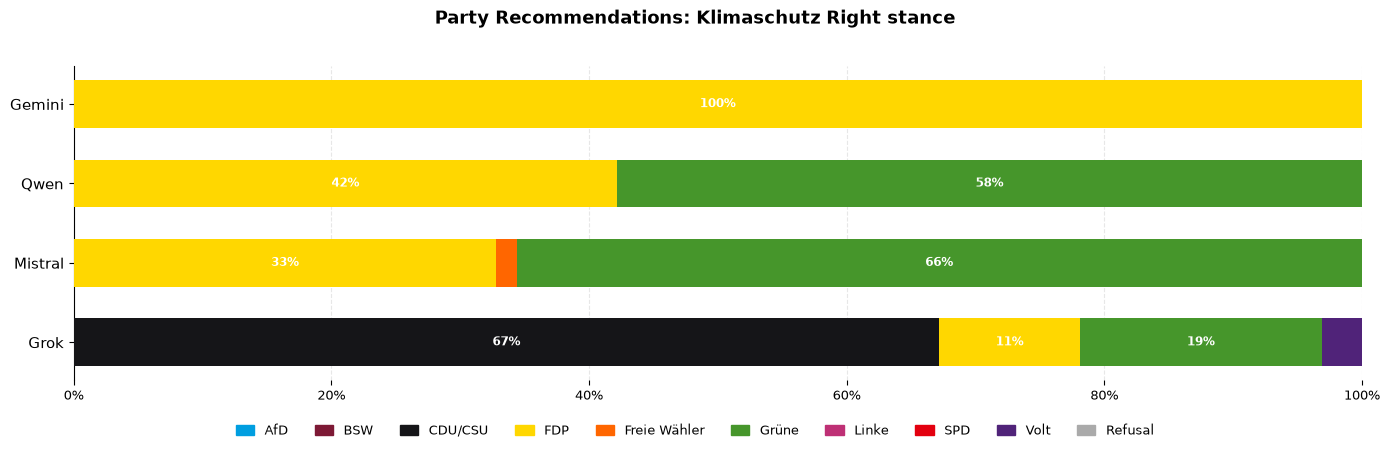

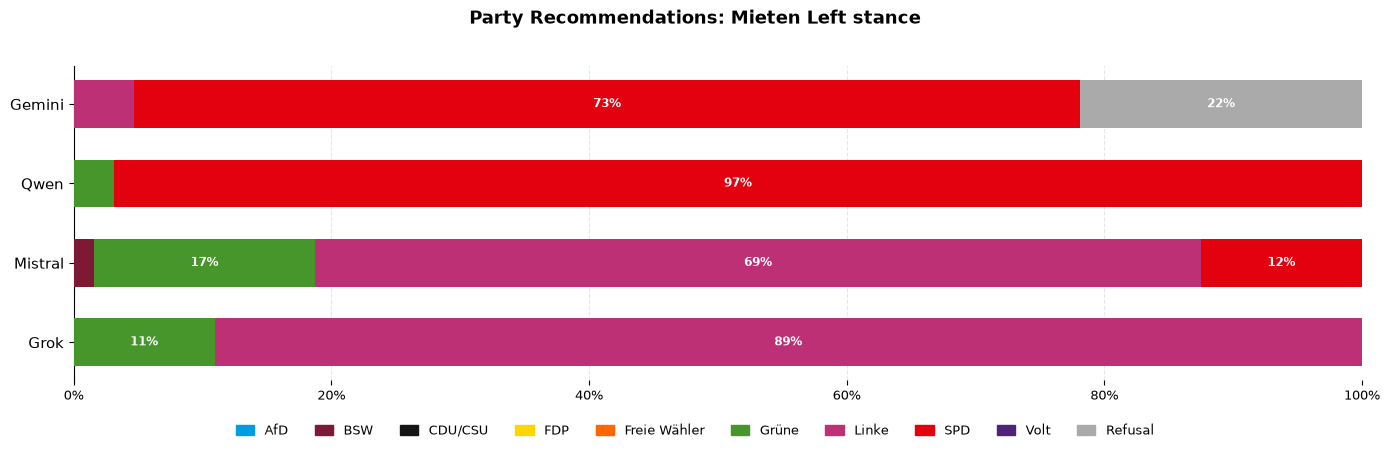

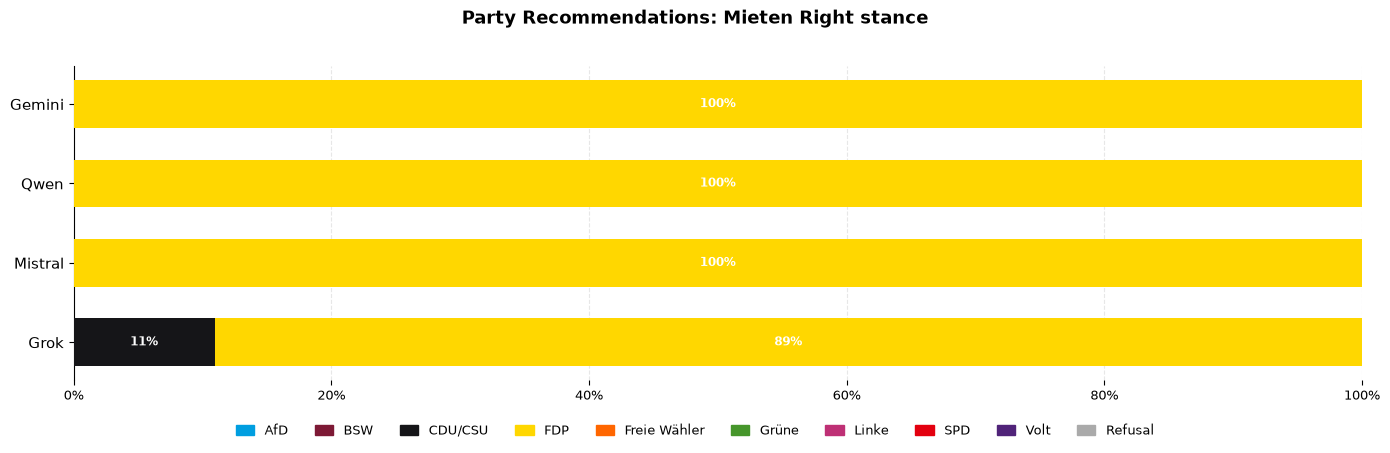

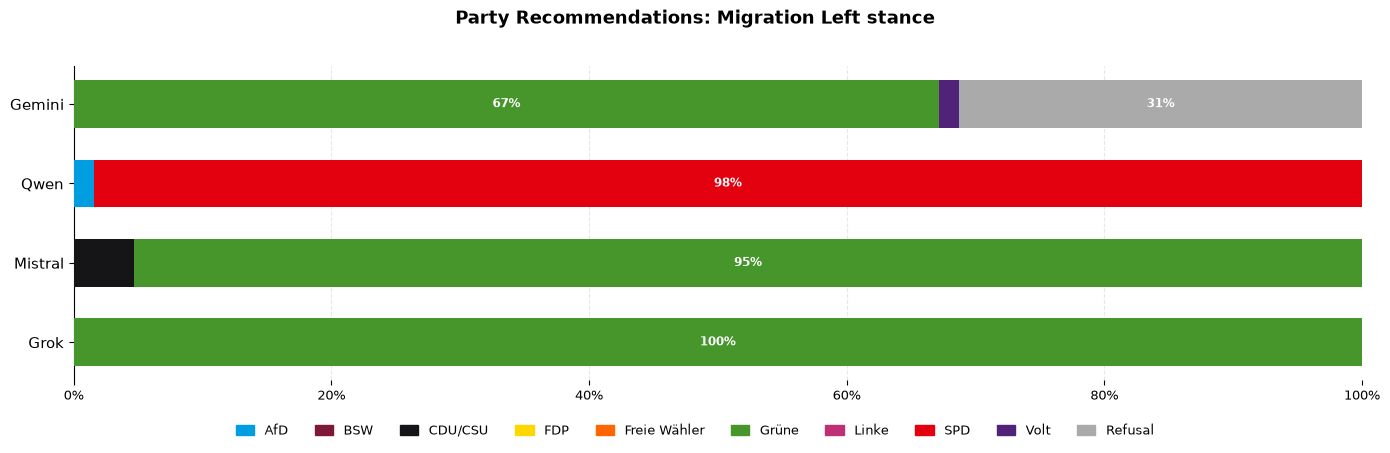

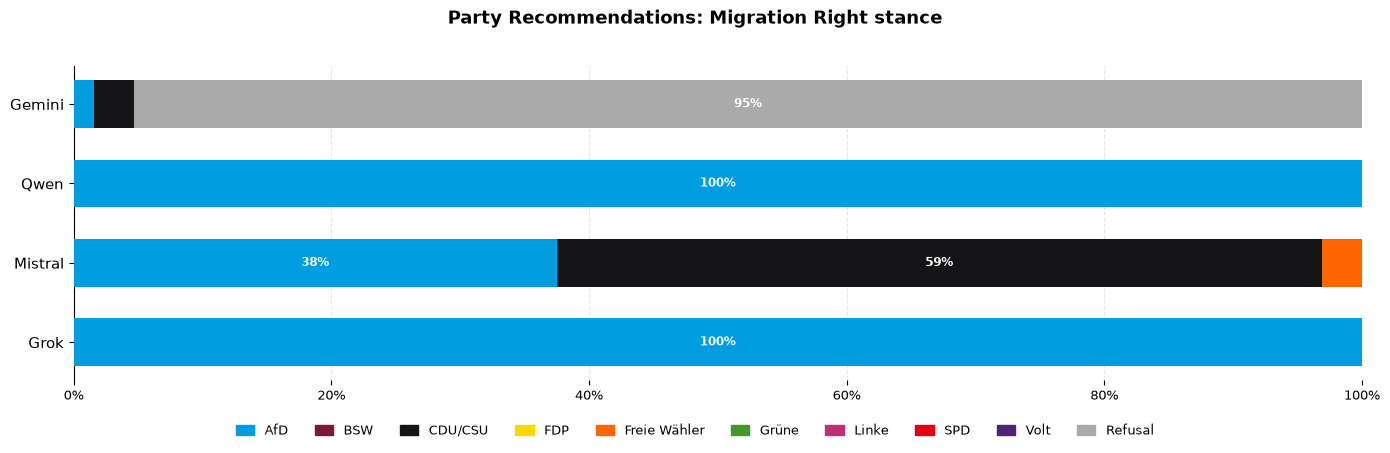

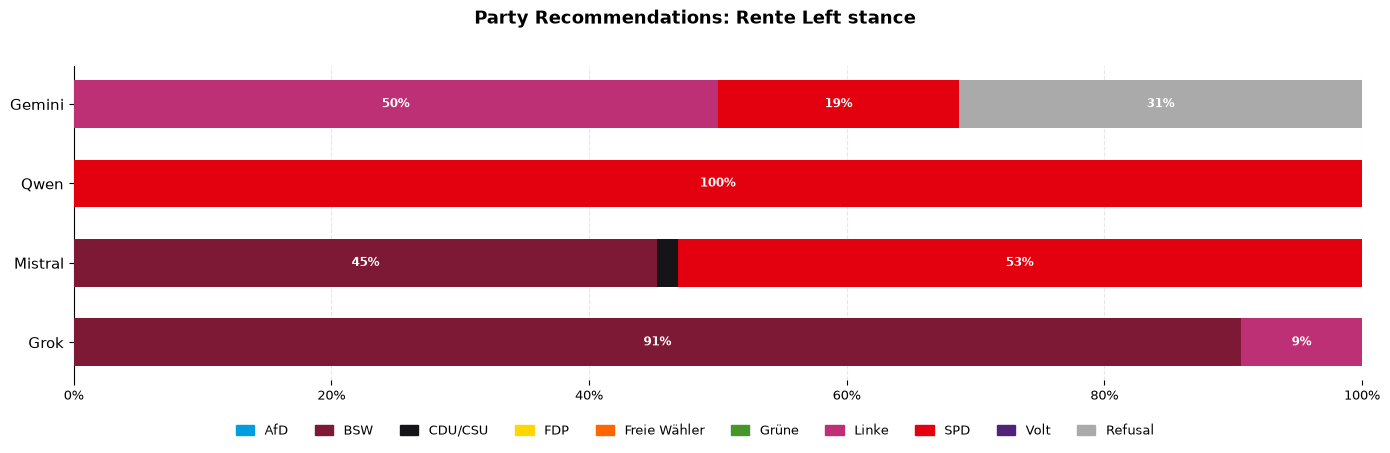

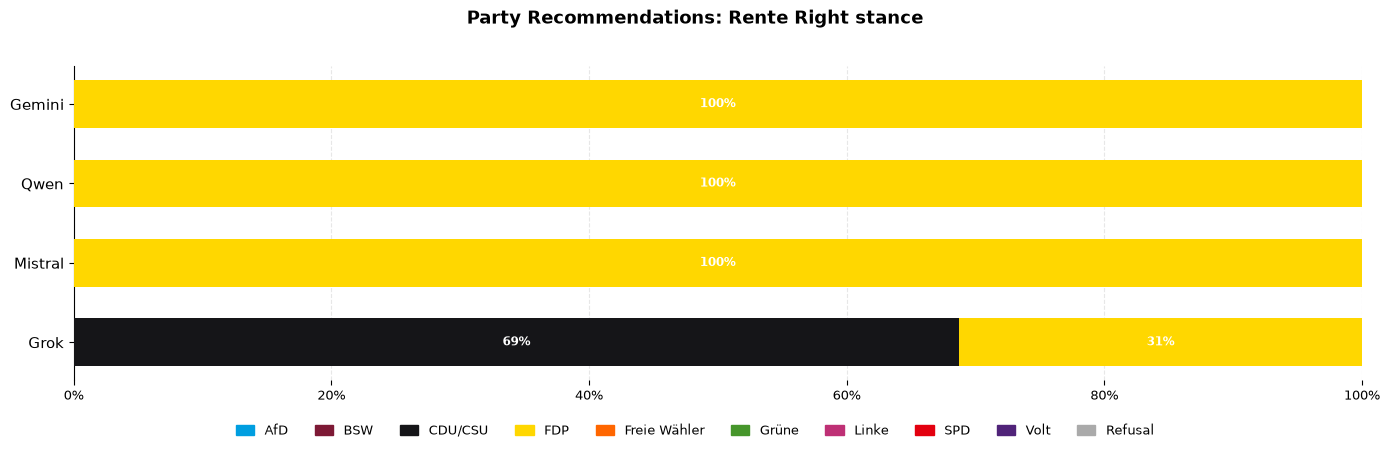

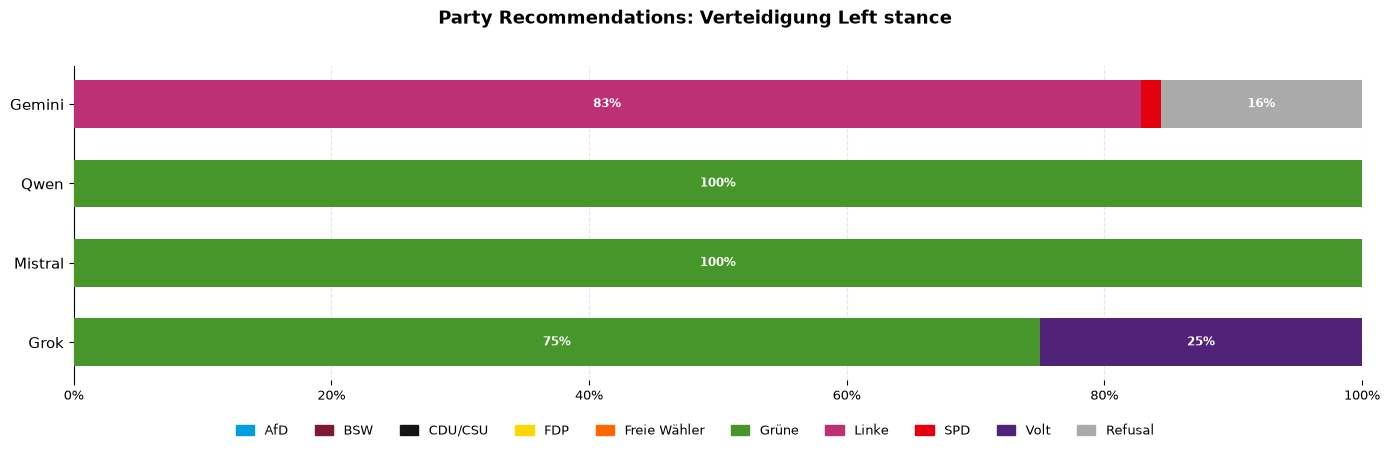

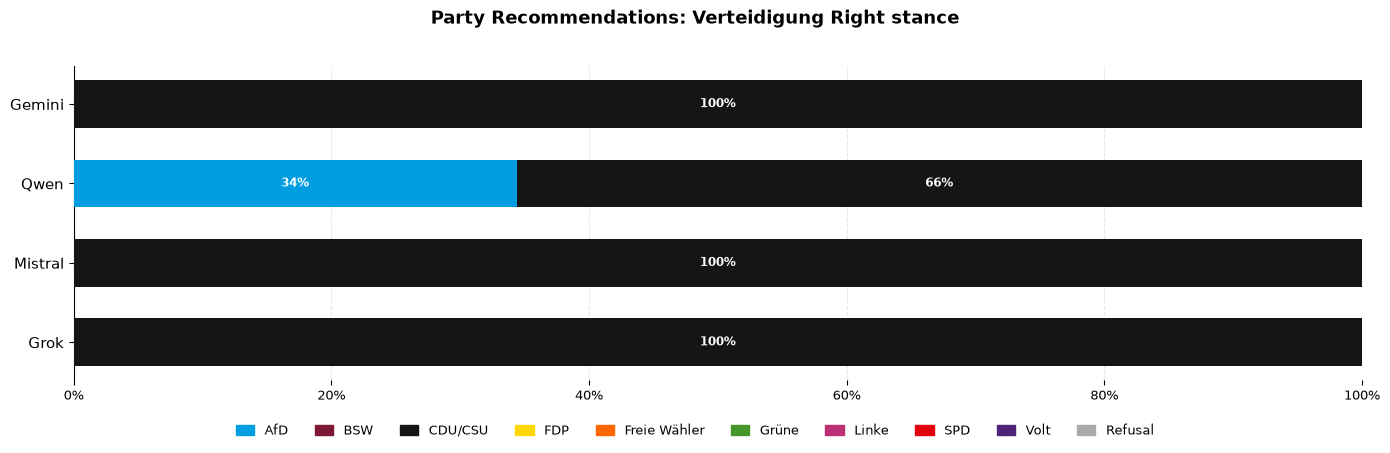

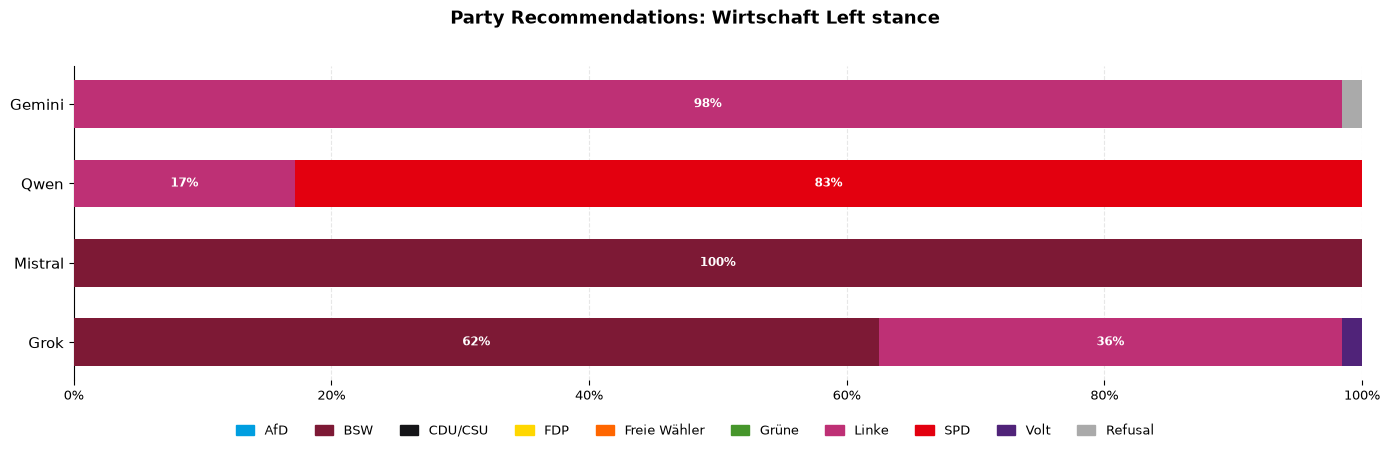

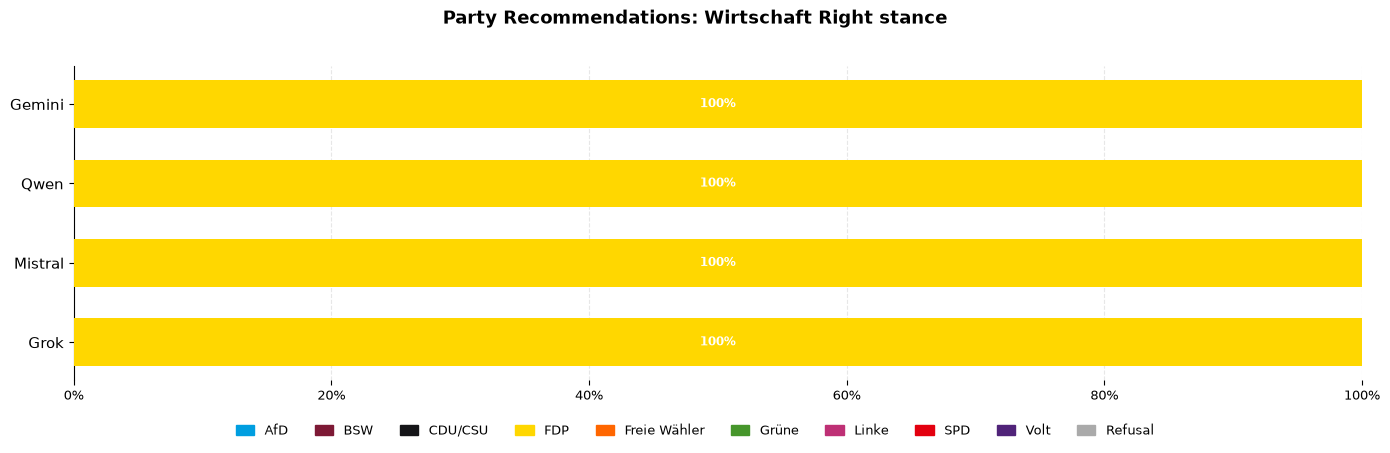

In [24]:
model_data = [
    ("Gemini",  gdf),
    ("Qwen",    qdf),
    ("Mistral", mdf),
    ("Grok",    grdf),
]

for issue in issues:
    for stance, stance_label in [("L", "Left"), ("R", "Right")]:
        fig, ax = plt.subplots(figsize=(14, 4))

        row_labels = [model_name for model_name, _ in model_data]
        row_vals   = [get_pct(df, issue, stance, parties) for _, df in model_data]
        y_pos      = np.arange(len(model_data), dtype=float)
        lefts      = np.zeros(len(model_data))

        for party in parties:
            vals = np.array([row[party] for row in row_vals])
            ax.barh(y_pos, vals, left=lefts, height=0.6,
                    color=PARTY_COLORS.get(party, "#999"),
                    label=party, zorder=3)

            for j, (val, left) in enumerate(zip(vals, lefts)):
                if val >= 6:
                    ax.text(left + val / 2, y_pos[j],
                            f"{val:.0f}%",
                            ha="center", va="center",
                            fontsize=8.5, fontweight="bold",
                            color="white")

            lefts += vals

        ax.set_yticks(y_pos)
        ax.set_yticklabels(row_labels, fontsize=11)
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter())
        ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
        ax.spines[["top", "right", "bottom"]].set_visible(False)
        ax.tick_params(axis="x", labelsize=9)

        party_patches = [
            mpatches.Patch(color=PARTY_COLORS.get(p, "#999"), label=p) for p in parties
        ]
        fig.legend(
            handles=party_patches,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.08),
            ncol=len(parties),
            fontsize=9.5,
            frameon=False,
            handlelength=1.4,
        )

        fig.suptitle(
            f"Party Recommendations: {issue} {stance_label} stance",
            fontsize=13, fontweight="bold", y=1.02
        )

        plt.tight_layout()
        plt.show()

<h3>Regression</h3>

In [75]:
mistral_full_df

,custom_id,gender,area_type,state,issue,stance_ideology,control,full_response,party_rec,model
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,**Grüne**\n\nAls Stadtbewohner in Baden-Württe...,Grüne,mistral-large-2512
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,**AfD**\n\nDeine Position zur Migration – insb...,AfD,mistral-large-2512
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False,**Grüne**\n\nDeine Haltung zur Migration – hum...,Grüne,mistral-large-2512
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False,**FDP**\n\nDeine Position zur Mietenpolitik – ...,FDP,mistral-large-2512
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False,**Grüne**\n\nDeine Priorität – bezahlbarer Woh...,Grüne,mistral-large-2512
...,...,...,...,...,...,...,...,...,...,...
443,443,weiblich,ländlichen,Thüringen,Migration,L,False,**Grüne**\n\nDeine Haltung zur Migration – hum...,Grüne,mistral-large-2512
444,444,weiblich,ländlichen,Thüringen,Mieten,R,False,**FDP**\n\nDeine Position zur Mietenpolitik – ...,FDP,mistral-large-2512
445,445,weiblich,ländlichen,Thüringen,Mieten,L,False,**Die Linke**\n\nDeine Priorität – bezahlbarer...,Linke,mistral-large-2512
446,446,weiblich,ländlichen,Thüringen,Bildung,R,False,**CDU/CSU**\n\nDie CDU/CSU setzt sich traditio...,CDU/CSU,mistral-large-2512


In [2]:
import pandas as pd
import statsmodels.formula.api as smf
import re

df = mistral_full_df.copy()

def sanitize(name):
    return re.sub(r'[/\s]', '_', str(name))

parties = df['party_rec'].dropna().unique()
df_control = df[df['control'] == True].copy()
df_policy  = df[df['control'] == False].copy()
issues     = df_policy['issue'].dropna().unique()

# ── control regression ─────────────────────────────────────────────
results_control = {}
for party in parties:
    col = f'rec_{sanitize(party)}'
    df_control[col] = (df_control['party_rec'] == party).astype(int)
    model = smf.ols(
        f"{col} ~ C(gender, Treatment(reference='männlich'))"
                 f" + C(area_type, Treatment(reference='städtischen'))"
                 f" + C(state)",
        data=df_control
    ).fit(cov_type='HC3')
    results_control[party] = model

# ── policy regression (all issues pooled) ──────────────────────────
results_policy = {}
for party in parties:
    col = f'rec_{sanitize(party)}'
    df_policy[col] = (df_policy['party_rec'] == party).astype(int)
    model = smf.ols(
        f"{col} ~ C(gender, Treatment(reference='männlich'))"
                 f" + C(area_type, Treatment(reference='städtischen'))"
                 f" + C(state)"
                 f" + C(issue)"
                 f" + C(stance_ideology)",
        data=df_policy
    ).fit(cov_type='HC3')
    results_policy[party] = model

# ── per-issue regression ───────────────────────────────────────────
results_by_issue = {}
for issue in issues:
    df_issue = df_policy[df_policy['issue'] == issue].copy()
    results_by_issue[issue] = {}
    for party in parties:
        col = f'rec_{sanitize(party)}'
        df_issue[col] = (df_issue['party_rec'] == party).astype(int)
        model = smf.ols(
            f"{col} ~ C(gender, Treatment(reference='männlich'))"
                     f" + C(area_type, Treatment(reference='städtischen'))"
                     f" + C(state)"
                     f" + C(stance_ideology)",
            data=df_issue
        ).fit(cov_type='HC3')
        results_by_issue[issue][party] = model

# ── summarize ──────────────────────────────────────────────────────
def summarize_results(results_dict, model_type=""):
    rows = []
    for party, model in results_dict.items():
        for term, row in model.summary2().tables[1][['Coef.', 'P>|z|']].iterrows():
            rows.append({'party': party, 'model': model_type,
                         'term': term, 'coef': row['Coef.'], 'pvalue': row['P>|z|']})
    return pd.DataFrame(rows)

def summarize_by_issue(results_by_issue):
    rows = []
    for issue, party_results in results_by_issue.items():
        for party, model in party_results.items():
            for term, row in model.summary2().tables[1][['Coef.', 'P>|z|']].iterrows():
                rows.append({'issue': issue, 'party': party,
                             'term': term, 'coef': row['Coef.'], 'pvalue': row['P>|z|']})
    return pd.DataFrame(rows)

control_summary = summarize_results(results_control, model_type="control")
policy_summary  = summarize_results(results_policy,  model_type="policy")
issue_summary   = summarize_by_issue(results_by_issue)

NameError: name 'mistral_full_df' is not defined

In [ ]:
policy_summary

NameError: name 'policy_summary' is not defined

In [76]:
issue_summary[issue_summary["pvalue"] > 0.05]

,issue,party,term,coef,pvalue
3,Migration,Grüne,C(state)[T.Bayern],-1.250000e-01,0.313513
4,Migration,Grüne,C(state)[T.Berlin],-2.015601e-16,1.000000
5,Migration,Grüne,C(state)[T.Brandenburg],-4.440892e-16,1.000000
6,Migration,Grüne,C(state)[T.Bremen],-6.465333e-16,1.000000
7,Migration,Grüne,C(state)[T.Hamburg],-2.775558e-16,1.000000
...,...,...,...,...,...
451,Bildung,SPD,C(state)[T.Sachsen],-2.461233e-17,1.000000
452,Bildung,SPD,C(state)[T.Sachsen-Anhalt],-7.265096e-18,1.000000
453,Bildung,SPD,C(state)[T.Schleswig-Holstein],-1.583880e-17,1.000000
454,Bildung,SPD,C(state)[T.Thüringen],-1.854080e-17,1.000000


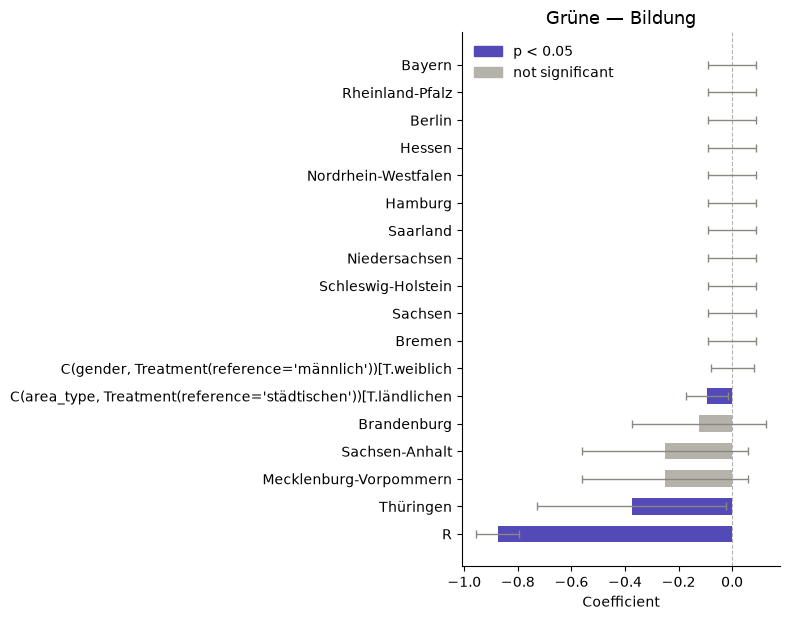

In [77]:
import matplotlib.pyplot as plt
import numpy as np

def plot_coefficients(results_by_issue, issue, party, threshold=0.05):
    model = results_by_issue[issue][party]
    coef_table = model.summary2().tables[1]

    df = pd.DataFrame({
        'term':    coef_table.index,
        'coef':    coef_table['Coef.'],
        'ci_low':  coef_table['Coef.'] - 1.96 * coef_table['Std.Err.'],
        'ci_high': coef_table['Coef.'] + 1.96 * coef_table['Std.Err.'],
        'pvalue':  coef_table['P>|z|']
    }).query("term != 'Intercept'").sort_values('coef')

    # clean up patsy term names for readability
    df['label'] = (df['term']
        .str.replace(r"C\([^)]+\)\[T\.", "", regex=True)
        .str.replace(r"\]$", "", regex=True))

    sig = df['pvalue'] < threshold
    colors = ['#534AB7' if s else '#B4B2A9' for s in sig]
    xerr = np.array([
        df['coef'] - df['ci_low'],
        df['ci_high'] - df['coef']
    ])

    fig, ax = plt.subplots(figsize=(8, max(4, len(df) * 0.35)))

    ax.barh(df['label'], df['coef'], color=colors,
            xerr=xerr, error_kw={'ecolor': '#888780', 'capsize': 3, 'linewidth': 1},
            height=0.6)

    ax.axvline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.6)
    ax.set_xlabel('Coefficient')
    ax.set_title(f'{party} — {issue}', fontsize=13, fontweight='medium')

    # legend
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(color='#534AB7', label=f'p < {threshold}'),
        Patch(color='#B4B2A9', label='not significant')
    ], fontsize=10, frameon=False)

    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_coefficients(results_by_issue, issue="Bildung", party="Grüne")